# 01. SECOM 데이터 확인

공정 측정값과 검사 결과를 읽고 데이터 분포와 결측치를 확인한다.

출처: [UCI SECOM](https://archive.ics.uci.edu/dataset/179/secom)

원본 파일은 프로젝트의 `data/raw` 폴더에 둔다.
측정 항목의 구체적인 의미가 공개되지 않아 임의로 온도·압력 등의 이름을 붙이지 않는다.

## 1. 공정 측정값 읽기

공백으로 구분된 원본 측정값을 읽고 크기와 처음 5개 행을 확인한다.

In [1]:
from pathlib import Path
import pandas as pd

# 실행 위치가 프로젝트 최상위인지 notebooks 폴더인지 확인
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data" / "raw"

# 공백으로 구분된 측정값 파일 읽기
X = pd.read_csv(
    data_dir / "secom.data",
    sep=r"\s+",
    header=None
)

print("데이터 크기:", X.shape)
X.head()

데이터 크기: (1567, 590)


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


## 2. 검사 결과 읽기

검사 결과와 검사 시각을 읽고 측정값과 행 수가 같은지 확인한다.
원본 두 파일의 같은 행끼리 대응하므로 행 순서를 유지한다.

In [2]:
# 정답 파일: 검사 결과 + 검사 시각
labels = pd.read_csv(
    data_dir / "secom_labels.data",
    sep=r"\s+",
    header=None,
    names=["result", "timestamp"]
)

print("정답 데이터 크기:", labels.shape)
print("측정값과 정답의 행 수 일치:", len(X) == len(labels))

labels.head()


정답 데이터 크기: (1567, 2)
측정값과 정답의 행 수 일치: True


,result,timestamp
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00


## 3. 정답 변환 및 분포 확인

정상(-1)은 0, 불량(1)은 1로 변환한다.
변환 실패 개수와 정상·불량 개수 및 비율을 확인한다.

In [3]:
# 원본 정답을 정상 0, 불량 1로 변환
y = labels["result"].map({-1: 0, 1: 1})
y.name = "is_defect"

print("정답 변환 실패 개수:", y.isna().sum())
print("정상 개수:", (y == 0).sum())
print("불량 개수:", (y == 1).sum())
print(f"불량 비율: {y.mean():.2%}")

정답 변환 실패 개수: 0
정상 개수: 1463
불량 개수: 104
불량 비율: 6.64%


불량 비율은 약 6.64%로 정상보다 적다.
모두 정상으로 예측해도 정확도가 약 93.36%이므로,
이후에는 불량 Recall·Precision·F1과 혼동행렬도 함께 확인한다.


## 4. 정상·불량 분포 시각화

정상과 불량의 개수 및 비율을 막대그래프로 비교한다.

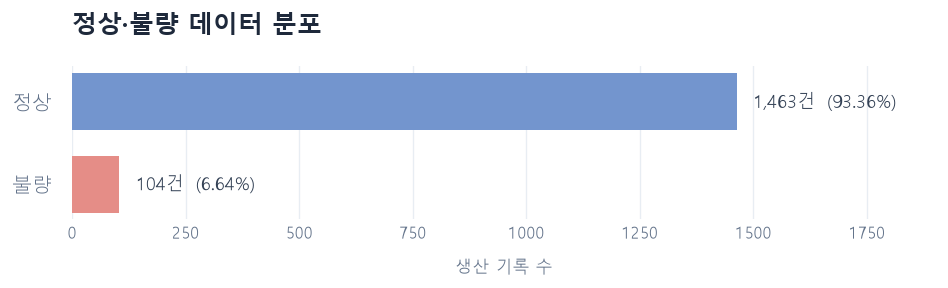

In [4]:
import matplotlib.pyplot as plt

counts = y.value_counts().reindex([0, 1], fill_value=0)
ratios = counts / counts.sum()

with plt.rc_context({"font.family": "Malgun Gothic"}):
    fig, ax = plt.subplots(figsize=(8, 2.5), dpi=120)

    positions = [0, 0.65]

    bars = ax.barh(
        positions,
        counts.to_numpy(),
        height=0.45,
        color=["#7395CE", "#E58D87"]
    )

    ax.set_yticks(positions, labels=["정상", "불량"])

    # 정상 → 불량 순서
    ax.invert_yaxis()

    # 막대 오른쪽에 개수와 비율 표시
    for bar, count, ratio in zip(bars, counts, ratios):
        ax.text(
            count + counts.max() * 0.025,
            bar.get_y() + bar.get_height() / 2,
            f"{count:,}건  ({ratio:.2%})",
            va="center",
            fontsize=11,
            color="#334155"
        )

    ax.set_title(
        "정상·불량 데이터 분포",
        loc="left",
        fontsize=15,
        fontweight="bold",
        color="#1E293B",
        pad=20
    )
    ax.set_xlabel("생산 기록 수", color="#64748B", labelpad=10)
    ax.set_xlim(0, counts.max() * 1.3)

    # 테두리를 없애고 옅은 눈금선만 표시
    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E8EDF3", linewidth=0.8)
    ax.tick_params(axis="both", length=0, labelcolor="#64748B")
    ax.tick_params(axis="y", labelsize=12, pad=12)

    plt.tight_layout()
    plt.show()

## 5. 결측치 확인

전체 결측치 개수와 결측치가 있는 열 수를 확인한다.
결측치 비율이 높은 항목 10개를 표시한다.

In [6]:
# 열별 결측치 개수와 비율
missing_count = X.isna().sum()
missing_ratio = X.isna().mean()

missing_summary = pd.DataFrame({
    "결측치 개수": missing_count,
    "결측치 비율": missing_ratio
})

# 결측치 비율이 높은 순서로 정렬
missing_summary = missing_summary.sort_values(
    "결측치 비율",
    ascending=False
)

print("전체 결측치 개수:", missing_count.sum())
print("결측치가 있는 열 수:", (missing_count > 0).sum())
print("모든 값이 비어 있는 열 수:", (missing_ratio == 1).sum())

missing_summary.head(10)

전체 결측치 개수: 41951
결측치가 있는 열 수: 538
모든 값이 비어 있는 열 수: 0


,결측치 개수,결측치 비율
292,1429,0.911934
293,1429,0.911934
158,1429,0.911934
157,1429,0.911934
492,1341,0.855775
85,1341,0.855775
358,1341,0.855775
220,1341,0.855775
244,1018,0.649649
517,1018,0.649649


## 6. 값이 일정한 측정 항목 확인

결측치를 제외한 값이 한 종류뿐인 항목을 확인한다.
실제 제외할 항목과 결측치 처리 기준은 02 노트북에서 학습 데이터만으로 정한다.

In [7]:
# 결측치를 제외한 열별 고유값 개수
unique_count = X.nunique(dropna=True)

# 관측된 값이 한 종류뿐인 열
constant_columns = unique_count[unique_count == 1].index

print("값이 일정한 열 수:", len(constant_columns))
print("해당 열 번호:", constant_columns.tolist())

값이 일정한 열 수: 116
해당 열 번호: [5, 13, 42, 49, 52, 69, 97, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538]
